# Symulator Epidemii — Monte Carlo
Zadana ilość ludzi rusza się losowo po zadanej wielkości planszy 2D w zadanej ilości dni. W dniu 0 zadana ilość chorych zaraża innych z zadanym prawdopodobieństwem na zadanej odległości. Chorzy mają szansę z każdym nowym dniem na wyleczenie się z wirusa. 

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
# Parametry na start symulacji
SEED = 67 # seed
N = 1500 # liczba ludzi
GRID = 140 # rozmiar siatki 140x140
N_STEPS = 200 # czas trwania (dni)
INIT_INFECTED = 15 # początkowa liczba chorych
P_INFECT = 0.30 # prawd. zarazenia przy kontakcie
P_RECOVER = 0.01 # prawd. wyzdrowienia po minimalnym czasie choroby
CONTACT_RADIUS = 1 # maksymalna odleglosc na zarazenie
RECOVERY_DELAY = 7 # minimalna liczba dni choroby przed wyzdrowieniem

HEALTHY, INFECTED, RECOVERED, VACCINATED, QUARANTINED = 0, 1, 2, 3, 4
STATES = [HEALTHY, INFECTED, RECOVERED, VACCINATED, QUARANTINED]
COLORS = ["#00FF00", "#FF0000", "#A425A6", "#00FFFF", "#808080"]
LABELS = ["Zdrowy", "Chory", "Uzdrowiony", "Zaszczepiony", "Kwarantanna"]
# Możliwe ruchy (8 kierunków + stanie w miejscu)
MOVES = np.array([[-1,0], [-1,1], [0,1], [1,1], [1,0], [1,-1], [0,-1], [-1,-1], [0,0]], dtype=int)

def init_sim(n, grid, init_infected, rng):
    # Losujemy pozycje startowe X, Y dla każdego
    positions = rng.integers(0, grid, size=(n, 2))
    status = np.full(n, HEALTHY, dtype=int)
    days_infected = np.full(n, -1, dtype=int) # -1 znaczy, że ktoś jest zdrowy

    # Pacjenci zero
    if init_infected > 0:
        infected_count = min(init_infected, n)
        infected_idx = rng.choice(n, infected_count, replace=False)
        status[infected_idx] = INFECTED
        days_infected[infected_idx] = 0
    return positions, status, days_infected

def apply_quarantine(status, rng, fraction):
    #Wysyla losowe osoby do kwarantanny az do zadanego procentu populacji.
    if fraction <= 0:
        return status

    n = len(status)
    target = int(n * fraction)
    current = np.sum(status == QUARANTINED)
    if current >= target:
        return status

    candidates = np.where(status != QUARANTINED)[0]
    if candidates.size == 0:
        return status

    to_add = min(target - current, candidates.size)
    new_quarantine = rng.choice(candidates, to_add, replace=False)
    status[new_quarantine] = QUARANTINED
    return status

def move_people(positions, status, grid, rng):
    #Ruch o 1 kratke; kwarantanna stoi w miejscu.
    move_idx = rng.integers(0, len(MOVES), size=len(positions))
    move = MOVES[move_idx]
    move[status == QUARANTINED] = [0, 0]
    return (positions + move) % grid

def count_contacts(positions_a, positions_b, radius):
    #Liczy, ile osob z B jest blisko kazdej osoby z A. Uzywamy dystansu Chebysheva (maksymalna roznica wspolrzednych).
    if len(positions_a) == 0 or len(positions_b) == 0:
        return np.zeros(len(positions_a), dtype=int)
    diff = np.abs(positions_a[:, None] - positions_b[None])
    close = np.max(diff, axis=2) <= radius
    return close.sum(axis=1)

def step( positions, status, days_infected, rng, t, grid, p_infect, p_recover, contact_radius, recovery_delay, vax_start, vax_rate, lockdown_on, q_frac,):
    #Jeden dzien symulacji.
    n = len(positions)

    # 1) Kwarantanna
    if lockdown_on:
        status = apply_quarantine(status, rng, q_frac)
    # 2) Ruch
    positions = move_people(positions, status, grid, rng)
    # 3) Kto jest kim
    infected_idx = np.where(status == INFECTED)[0]
    healthy_idx = np.where(status == HEALTHY)[0]
    recovered_idx = np.where(status == RECOVERED)[0]

    # 4) Chorzy przechodza kolejny dzien choroby
    if infected_idx.size > 0:
        days_infected[infected_idx] += 1

    # 5) Zarazenie zdrowych
    if infected_idx.size > 0 and healthy_idx.size > 0:
        contacts = count_contacts( positions[healthy_idx],positions[infected_idx], contact_radius,)
        if np.any(contacts):
            prob = 1 - (1 - p_infect) ** contacts
            new_infected = healthy_idx[rng.random(healthy_idx.size) < prob]
            status[new_infected] = INFECTED
            days_infected[new_infected] = 0

    # 6) Ponowne zarazenie ozdrowiencow (polowa ryzyka)
    if infected_idx.size > 0 and recovered_idx.size > 0:
        contacts = count_contacts( positions[recovered_idx], positions[infected_idx], contact_radius,)
        if np.any(contacts):
            reduced_p = p_infect * 0.5
            prob = 1 - (1 - reduced_p) ** contacts
            new_infected = recovered_idx[rng.random(recovered_idx.size) < prob]
            status[new_infected] = INFECTED
            days_infected[new_infected] = 0

    # 7) Wyzdrowienia po minimalnym czasie choroby
    if infected_idx.size > 0:
        ready = infected_idx[days_infected[infected_idx] >= recovery_delay]
        if ready.size > 0:
            recovered_now = ready[rng.random(ready.size) < p_recover]
            status[recovered_now] = RECOVERED
            days_infected[recovered_now] = -1

    # 8) Szczepienia
    if vax_start is not None and t >= vax_start:
        candidates = np.where(status == HEALTHY)[0]
        if candidates.size > 0:
            n_vax = int(n * vax_rate)
            n_vax = min(n_vax, candidates.size)
            if n_vax > 0:
                new_vax = rng.choice(candidates, n_vax, replace=False)
                status[new_vax] = VACCINATED
    return positions, status, days_infected

def count_states(status):
    #Zlicza osoby w kazdym stanie.
    counts = np.zeros(len(STATES), dtype=int)
    for state in STATES:
        counts[state] = np.sum(status == state)
    return counts

def run_simulation( vax_start=None, vax_rate=0.0, lock_trigger=1.1, q_frac=0.0, snap_days=None, n=N, grid=GRID, n_steps=N_STEPS, init_infected=INIT_INFECTED, p_infect=P_INFECT, p_recover=P_RECOVER, contact_radius=CONTACT_RADIUS, recovery_delay=RECOVERY_DELAY, seed=SEED,):
    #Glowna petla symulacji.
    rng = np.random.default_rng(seed)
    positions, status, days_infected = init_sim(n, grid, init_infected, rng)
    curves = np.zeros((n_steps, len(STATES)), dtype=int)
    snaps = {}
    snap_set = set(snap_days) if snap_days else set()
    lockdown_active = False
    for day in range(n_steps):
        curves[day] = count_states(status)
        infected_fraction = curves[day, INFECTED] / n
        if infected_fraction >= lock_trigger:
            lockdown_active = True
        if day in snap_set:
            snaps[day] = (positions.copy(), status.copy())
        positions, status, days_infected = step( positions, status, days_infected, rng, day, grid, p_infect, p_recover, contact_radius, recovery_delay, vax_start, vax_rate, lockdown_active,q_frac,)
    return curves, snaps

def make_legend_handles():
    return [mpatches.Patch(color=c, label=l) for c, l in zip(COLORS, LABELS)]

def plot_snapshot(positions, status, ax, title):
    #Rysuje plansze w danym dniu.
    ax.set_facecolor("#1a1b3f")
    for state, color, label in zip(STATES, COLORS, LABELS):
        points = positions[status == state]
        if len(points) > 0:
            ax.scatter(points[:, 0], points[:, 1], c=color, s=6, zorder=2)
    ax.set_xlim(-1, GRID)
    ax.set_ylim(-1, GRID)
    ax.set_aspect("equal")
    ax.set_title(title, color="white", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


def plot_curve(curves, ax, title):
    #Rysuje przebieg liczby osob w czasie.
    t = np.arange(len(curves))
    ax.stackplot(t, curves[:, HEALTHY], curves[:, INFECTED], curves[:, RECOVERED], curves[:, VACCINATED], curves[:, QUARANTINED], colors=COLORS, labels=LABELS, alpha=0.85,)
    ax.set_xlabel("Dzien")
    ax.set_ylabel("Liczba ludzi")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=8)
    ax.set_ylim(0, N)


## Eksperyment 1 
Brak szczepień, brak kwarantanny, osoba uzdrowiona może zachorować ponownie. 
Podgląd 4 momentów czasowych + krzywa epidemii.

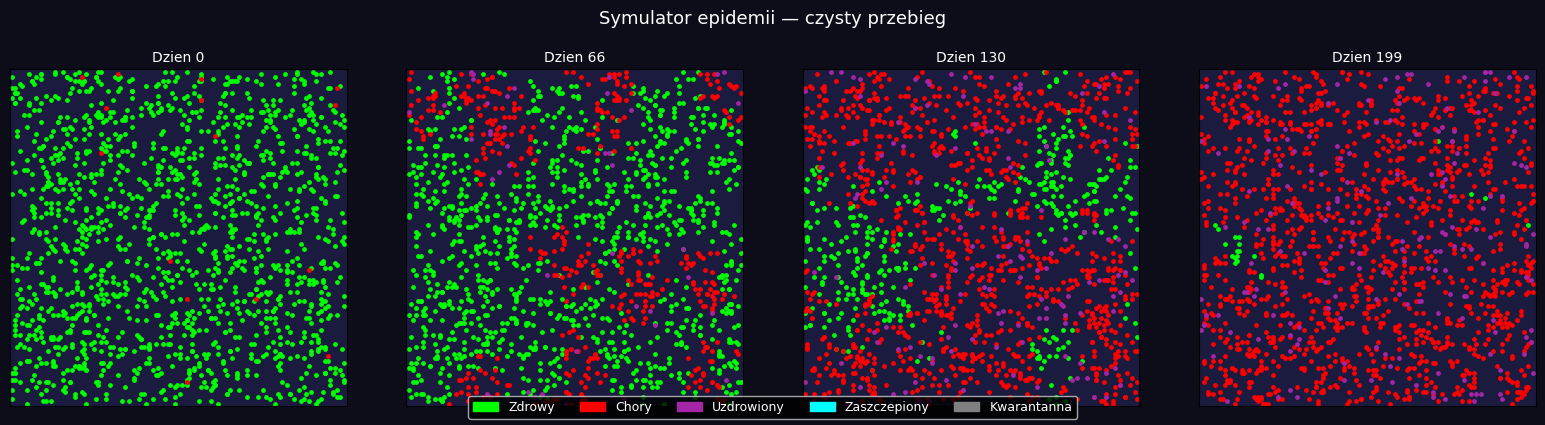

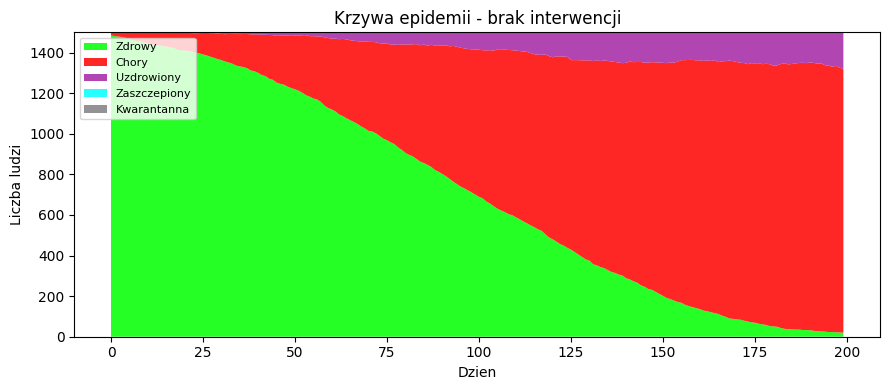

In [37]:
# Eksperyment 1 - opcja bazowa - bez szczepien i kwarantanny.
curves_base, snaps_base = run_simulation(snap_days={0, 66, 130, 199})

fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor="#0d0d1a")
for ax, day in zip(axes, sorted(snaps_base)):
    positions_day, status_day = snaps_base[day]
    plot_snapshot(positions_day, status_day, ax, f"Dzien {day}")

handles = make_legend_handles()
fig.legend(handles=handles, loc="lower center", ncol=5, facecolor="#000000", labelcolor="white", fontsize=9)
plt.suptitle("Symulator epidemii — czysty przebieg", color="white", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(9, 4))
plot_curve(curves_base, ax2, "Krzywa epidemii - brak interwencji")
plt.tight_layout()
plt.show()


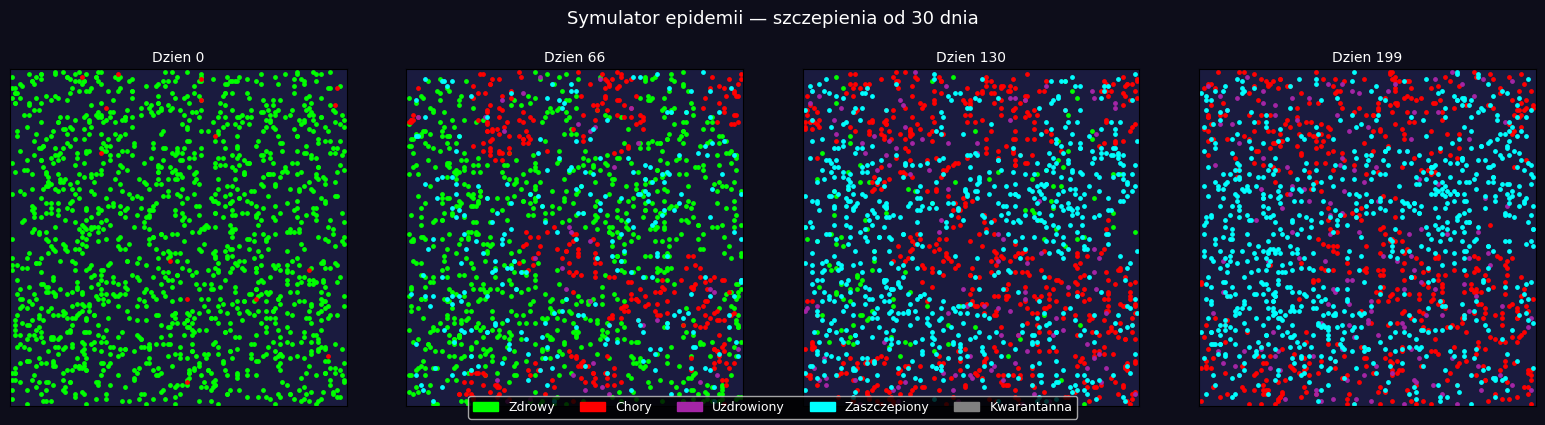

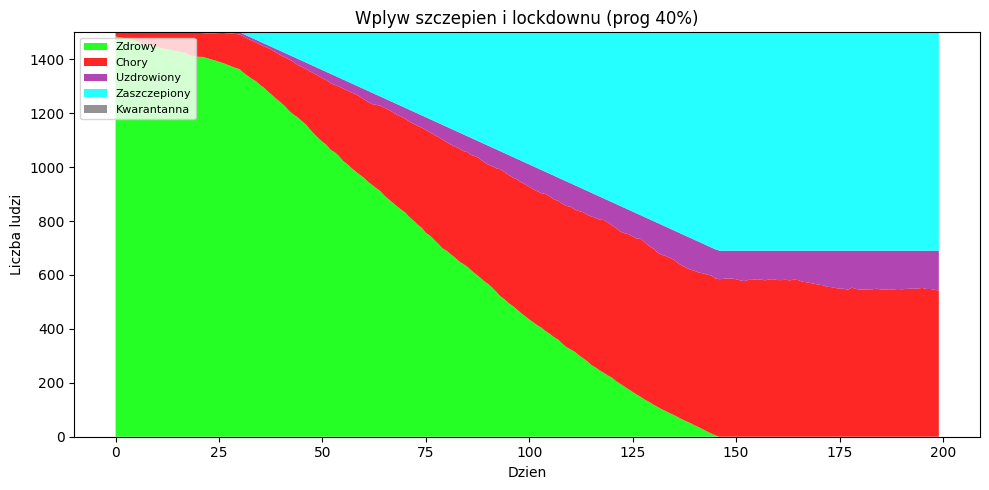

In [38]:
# Eksperyment 2 - szczepienia + ewentualny lockdown
curves_vax, snaps_vax = run_simulation( vax_start=30, vax_rate=0.005, lock_trigger=0.4, q_frac=0.8, snap_days={0, 66, 130, 199},)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor="#0d0d1a")
for ax, day in zip(axes, sorted(snaps_vax)):
    positions_day, status_day = snaps_vax[day]
    plot_snapshot(positions_day, status_day, ax, f"Dzien {day}")

handles = make_legend_handles()
fig.legend(handles=handles, loc="lower center", ncol=5, facecolor="#000000", labelcolor="white", fontsize=9)
plt.suptitle("Symulator epidemii — szczepienia od 30 dnia", color="white", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

fig_vax, ax_vax = plt.subplots(figsize=(10, 5))
plot_curve(curves_vax, ax_vax, "Wplyw szczepien i lockdownu (prog 40%)")
plt.tight_layout()
plt.show()


## Eksperyment 3: Kwarantanna Społeczna (Lockdown)

Jeśli w dowolnym dniu liczba aktywnych chorych osiągnie ustanowiony  ułamek (% chorych na całą populację), wdrażam tzw. stan "Kwarantanna". Zabezpiecza ona fizycznie określoną grupę zdrowych przed ruchami i wystawianiem się na chorujących w otoczeniu.

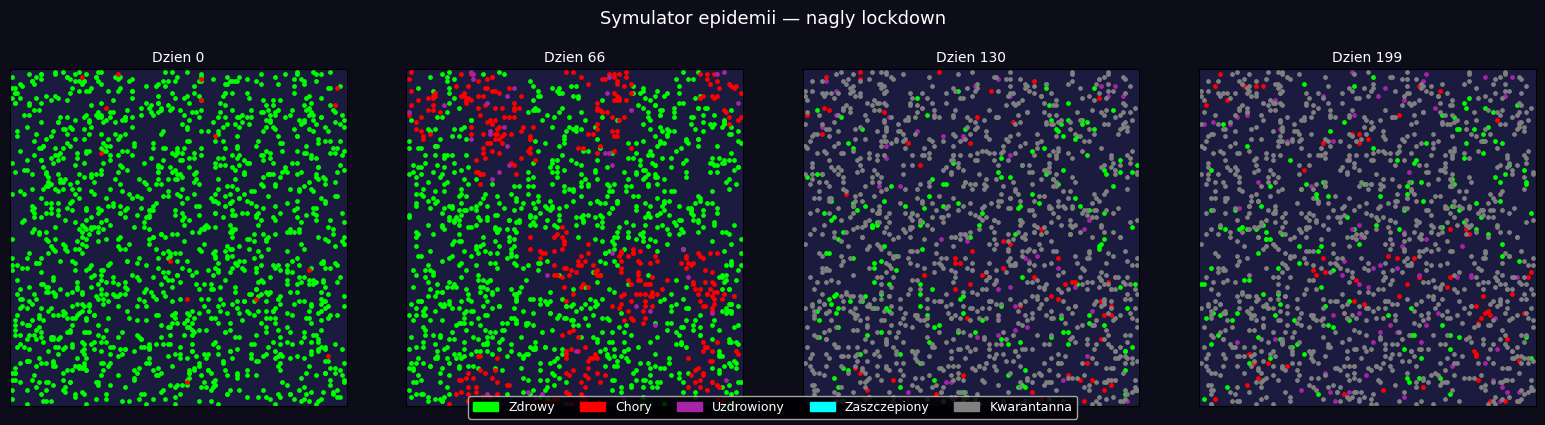

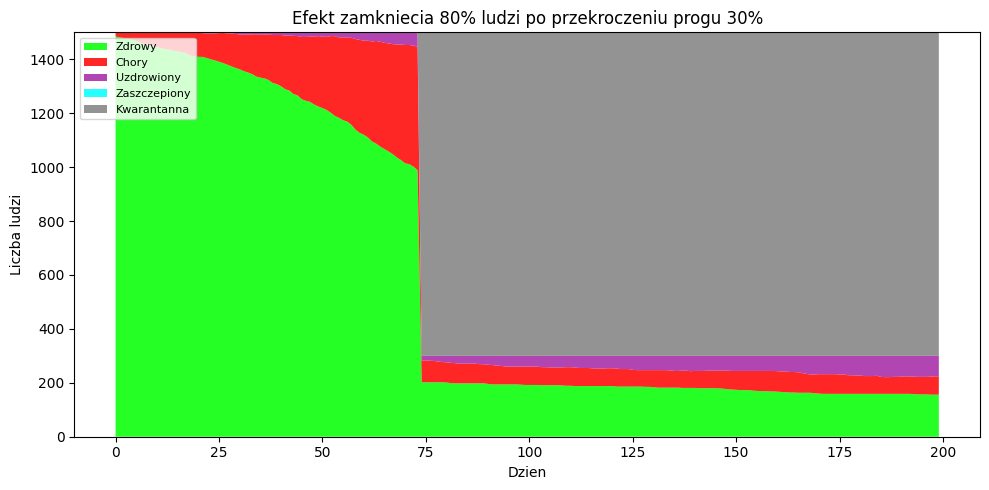

In [39]:
# Eksperyment 3 - sam lockdown (odciecie 80% przy progu 30% chorych)
curves_lock, snaps_lock = run_simulation(lock_trigger=0.30, q_frac=0.80, snap_days={0, 66, 130, 199})

fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor="#0d0d1a")
for ax, day in zip(axes, sorted(snaps_lock)):
    positions_day, status_day = snaps_lock[day]
    plot_snapshot(positions_day, status_day, ax, f"Dzien {day}")

handles = make_legend_handles()
fig.legend( handles=handles, loc="lower center", ncol=5, facecolor="#000000", labelcolor="white", fontsize=9)
plt.suptitle("Symulator epidemii — nagly lockdown", color="white", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

fig_lock, ax_lock = plt.subplots(figsize=(10, 5))
plot_curve(curves_lock, ax_lock, "Efekt zamkniecia 80% ludzi po przekroczeniu progu 30%")
plt.tight_layout()
plt.show()
